In [ ]:
# ============================================================
# CSE498R Thesis
# Stage 3: Pseudo-Supervised Local Refinement
#learning-based local refinement model
# ============================================================
#
# Goal:
# Improve local realism, sharpness, and seam quality
# after Stage 2 V2 output.
#
# Pipeline:
# Stage 2 V2 output -> pseudo-clean pool -> synthetic corruption
# -> local crop refinement training -> Stage 3 inference -> evaluation
# ============================================================

CELL 1 — Install dependencies

In [1]:
!pip -q install lpips

CELL 2 — Mount Google Drive

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


CELL 3 — Project paths

In [3]:
from pathlib import Path

# Main thesis root
PROJECT_ROOT = Path("/content/drive/MyDrive/CSE498R_Final_Thesis")

# Existing Stage 2 V2 output
STAGE2_NAME = "stage2_improved_v2"
STAGE2_ROOT = PROJECT_ROOT / "results" / STAGE2_NAME
STAGE2_IMG_ROOT = STAGE2_ROOT / "images"
STAGE2_META_ROOT = STAGE2_ROOT / "metadata"
STAGE2_CSV = STAGE2_META_ROOT / f"{STAGE2_NAME}_test.csv"

# New Stage 3 output
STAGE3_NAME = "stage3_refinement_v1"
STAGE3_ROOT = PROJECT_ROOT / "results" / STAGE3_NAME
STAGE3_IMG_ROOT = STAGE3_ROOT / "images"
STAGE3_META_ROOT = STAGE3_ROOT / "metadata"
STAGE3_CKPT_ROOT = STAGE3_ROOT / "checkpoints"

# Create Stage 3 folders
for p in [STAGE3_ROOT, STAGE3_IMG_ROOT, STAGE3_META_ROOT, STAGE3_CKPT_ROOT]:
    p.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT:", PROJECT_ROOT)
print("STAGE2_CSV:", STAGE2_CSV)
print("STAGE3_ROOT:", STAGE3_ROOT)

PROJECT_ROOT: /content/drive/MyDrive/CSE498R_Final_Thesis
STAGE2_CSV: /content/drive/MyDrive/CSE498R_Final_Thesis/results/stage2_improved_v2/metadata/stage2_improved_v2_test.csv
STAGE3_ROOT: /content/drive/MyDrive/CSE498R_Final_Thesis/results/stage3_refinement_v1


CELL 4 — Imports

In [4]:
import os
import json
import time
import math
import random
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

import lpips

CELL 5 — Configuration

In [5]:
CFG = {
    # pseudo-clean pool selection
    "max_residual_count": 0,
    "max_residual_conf": 0.10,
    "min_mask_pixels": 64,

    # local crop setting
    "crop_expand_ratio": 1.8,
    "crop_size": 256,

    # split
    "val_ratio": 0.20,
    "random_seed": 42,

    # training
    "batch_size": 8,
    "num_workers": 0,                                #initialy i kept 2
    "epochs": 20,
    "lr": 2e-4,
    "weight_decay": 1e-5,

    # loss weights
    "w_l1_full": 1.0,
    "w_l1_mask": 3.0,
    "w_grad": 0.5,

    # synthetic corruption
    "jpeg_quality_min": 30,
    "jpeg_quality_max": 70,
    "blur_kernel_choices": [3, 5, 7],
    "noise_sigma_min": 3.0,
    "noise_sigma_max": 12.0,
    "color_shift_max": 18,
    "halo_width_min": 3,
    "halo_width_max": 10,

    # blending
    "blend_blur_ksize": 25,

    # hardware
    "device": "cuda" if torch.cuda.is_available() else "cpu"
}

print(json.dumps(CFG, indent=2))

{
  "max_residual_count": 0,
  "max_residual_conf": 0.1,
  "min_mask_pixels": 64,
  "crop_expand_ratio": 1.8,
  "crop_size": 256,
  "val_ratio": 0.2,
  "random_seed": 42,
  "batch_size": 8,
  "num_workers": 0,
  "epochs": 20,
  "lr": 0.0002,
  "weight_decay": 1e-05,
  "w_l1_full": 1.0,
  "w_l1_mask": 3.0,
  "w_grad": 0.5,
  "jpeg_quality_min": 30,
  "jpeg_quality_max": 70,
  "blur_kernel_choices": [
    3,
    5,
    7
  ],
  "noise_sigma_min": 3.0,
  "noise_sigma_max": 12.0,
  "color_shift_max": 18,
  "halo_width_min": 3,
  "halo_width_max": 10,
  "blend_blur_ksize": 25,
  "device": "cuda"
}


CELL 6 — Reproducibility seed

In [6]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(CFG["random_seed"])
print("Seed fixed.")

Seed fixed.


CELL 7 — Utility functions

In [22]:
def read_rgb(path):
    return np.array(Image.open(path).convert("RGB"))

def read_gray(path):
    return np.array(Image.open(path).convert("L"))

def save_rgb(path, arr):
    Image.fromarray(arr.astype(np.uint8)).save(path)

def get_bbox_from_mask(mask):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0 or len(ys) == 0:
        return None
    x1, x2 = xs.min(), xs.max()
    y1, y2 = ys.min(), ys.max()
    return [int(x1), int(y1), int(x2), int(y2)]

def expand_bbox_to_square(bbox, image_shape, expand_ratio=1.8):
    h, w = image_shape[:2]
    x1, y1, x2, y2 = bbox

    bw = x2 - x1 + 1
    bh = y2 - y1 + 1
    side = int(max(bw, bh) * expand_ratio)

    cx = (x1 + x2) // 2
    cy = (y1 + y2) // 2

    nx1 = max(0, cx - side // 2)
    ny1 = max(0, cy - side // 2)
    nx2 = min(w - 1, nx1 + side - 1)
    ny2 = min(h - 1, ny1 + side - 1)

    side_x = nx2 - nx1 + 1
    side_y = ny2 - ny1 + 1
    side = min(side_x, side_y)

    nx2 = nx1 + side - 1
    ny2 = ny1 + side - 1

    return [int(nx1), int(ny1), int(nx2), int(ny2)]

def crop_by_bbox(img, bbox):
    x1, y1, x2, y2 = bbox
    return img[y1:y2+1, x1:x2+1]

def tensor_from_rgb(img):
    return torch.from_numpy(img.transpose(2, 0, 1)).float() / 255.0

def tensor_from_mask(mask):
    return torch.from_numpy(mask[None, ...]).float() / 255.0

def laplacian_var(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return float(cv2.Laplacian(gray, cv2.CV_64F).var())

def masked_laplacian_var(img_rgb, mask):
    # Make sure image and mask have exactly same H,W
    h = min(img_rgb.shape[0], mask.shape[0])
    w = min(img_rgb.shape[1], mask.shape[1])

    img_rgb = img_rgb[:h, :w]
    mask = mask[:h, :w]

    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    lap = cv2.Laplacian(gray, cv2.CV_64F)

    valid = (mask > 0)
    vals = lap[valid]

    if len(vals) == 0:
        return 0.0
    return float(vals.var())

def soft_blend_patch(base_img, refined_patch, local_mask, bbox, blur_ksize=25):
    x1, y1, x2, y2 = bbox
    out = base_img.copy()

    target_h = y2 - y1 + 1
    target_w = x2 - x1 + 1

    if refined_patch.shape[:2] != (target_h, target_w):
        refined_patch = cv2.resize(
            refined_patch,
            (target_w, target_h),
            interpolation=cv2.INTER_CUBIC
        )

    if local_mask.shape[:2] != (target_h, target_w):
        local_mask = cv2.resize(
            local_mask,
            (target_w, target_h),
            interpolation=cv2.INTER_NEAREST
        )

    base_patch = out[y1:y2+1, x1:x2+1]

    h = min(base_patch.shape[0], refined_patch.shape[0], local_mask.shape[0])
    w = min(base_patch.shape[1], refined_patch.shape[1], local_mask.shape[1])

    base_patch = base_patch[:h, :w].astype(np.float32)
    refined_patch = refined_patch[:h, :w].astype(np.float32)
    local_mask = local_mask[:h, :w]

    mask = (local_mask > 0).astype(np.float32)
    if blur_ksize % 2 == 0:
        blur_ksize += 1
    mask = cv2.GaussianBlur(mask, (blur_ksize, blur_ksize), 0)
    mask = np.clip(mask, 0.0, 1.0)[..., None]

    fused = refined_patch * mask + base_patch * (1.0 - mask)
    fused = np.clip(fused, 0, 255).astype(np.uint8)

    out[y1:y1+h, x1:x1+w] = fused
    return out

CELL 8 — Load Stage 2 results

In [8]:
df2 = pd.read_csv(STAGE2_CSV)

print("Total Stage 2 rows:", len(df2))
display(df2.head())

Total Stage 2 rows: 16


,id,final_mask_area_ratio,local_method,residual_count,residual_max_conf,global_time_sec,local_time_sec,total_time_sec,psnr_region,ssim_region,lpips_full,out_ssim,second_pass_used,feather_blur_ksize,mask_smooth_kernel
0,000006_000000006954,0.473184,diffusion_local,0,0.0,3.176752,6.482373,9.659125,14.279602,0.518027,0.331307,0.614847,False,31,11
1,000011_000000013659,0.332209,diffusion_local,0,0.0,4.852379,6.030985,10.883364,15.249033,0.712582,0.213151,0.774334,False,31,11
2,000021_000000054593,0.311797,diffusion_local,0,0.0,0.717063,5.771570,6.488634,13.728834,0.412951,0.223745,0.547767,False,31,11
3,000024_000000064523,0.478202,diffusion_local,0,0.0,2.434064,5.693230,8.127294,9.889632,0.340381,0.341583,0.627805,False,31,11
4,000063_000000176857,0.328529,diffusion_local,0,0.0,0.713700,5.725886,6.439585,11.632494,0.459866,0.231934,0.766431,False,31,11


CELL 9 — Build pseudo-clean pool

In [9]:
pool_rows = []

for _, row in df2.iterrows():
    sample_id = row["id"]

    input_path = STAGE2_IMG_ROOT / f"{sample_id}_input.png"
    final_result_path = STAGE2_IMG_ROOT / f"{sample_id}_final_result.png"
    final_mask_path = STAGE2_IMG_ROOT / f"{sample_id}_final_mask.png"

    if not input_path.exists():
        continue
    if not final_result_path.exists():
        continue
    if not final_mask_path.exists():
        continue

    mask = read_gray(final_mask_path)
    mask_pixels = int((mask > 0).sum())

    if mask_pixels < CFG["min_mask_pixels"]:
        continue

    if row["residual_count"] <= CFG["max_residual_count"] and row["residual_max_conf"] <= CFG["max_residual_conf"]:
        pool_rows.append({
            "id": sample_id,
            "input_path": str(input_path),
            "final_result_path": str(final_result_path),
            "final_mask_path": str(final_mask_path),
            "residual_count": row["residual_count"],
            "residual_max_conf": row["residual_max_conf"],
            "mask_pixels": mask_pixels,
            "psnr_region": row.get("psnr_region", np.nan),
            "ssim_region": row.get("ssim_region", np.nan),
            "lpips_full": row.get("lpips_full", np.nan),
            "out_ssim": row.get("out_ssim", np.nan),
        })

pool_df = pd.DataFrame(pool_rows)

print("Pseudo-clean pool size:", len(pool_df))
display(pool_df.head())

pool_df.to_csv(STAGE3_META_ROOT / "pseudo_clean_pool.csv", index=False)

Pseudo-clean pool size: 15


,id,input_path,final_result_path,final_mask_path,residual_count,residual_max_conf,mask_pixels,psnr_region,ssim_region,lpips_full,out_ssim
0,000006_000000006954,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,0,0.0,581449,14.279602,0.518027,0.331307,0.614847
1,000011_000000013659,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,0,0.0,408219,15.249033,0.712582,0.213151,0.774334
2,000021_000000054593,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,0,0.0,340831,13.728834,0.412951,0.223745,0.547767
3,000024_000000064523,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,0,0.0,543544,9.889632,0.340381,0.341583,0.627805
4,000063_000000176857,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,/content/drive/MyDrive/CSE498R_Final_Thesis/re...,0,0.0,403696,11.632494,0.459866,0.231934,0.766431


CELL 10 — Split train and validation

In [10]:
assert len(pool_df) >= 4, "Pseudo-clean pool is too small. Relax threshold a little if needed."

train_df, val_df = train_test_split(
    pool_df,
    test_size=CFG["val_ratio"],
    random_state=CFG["random_seed"],
    shuffle=True
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Train size:", len(train_df))
print("Validation size:", len(val_df))

train_df.to_csv(STAGE3_META_ROOT / "train_split.csv", index=False)
val_df.to_csv(STAGE3_META_ROOT / "val_split.csv", index=False)

Train size: 12
Validation size: 3


CELL 11 — Synthetic corruption functions

In [11]:
def apply_jpeg_compression(img_rgb, quality):
    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), int(quality)]
    ok, enc = cv2.imencode(".jpg", cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR), encode_param)
    if not ok:
        return img_rgb.copy()
    dec = cv2.imdecode(enc, cv2.IMREAD_COLOR)
    return cv2.cvtColor(dec, cv2.COLOR_BGR2RGB)

def add_gaussian_noise(img_rgb, sigma):
    noise = np.random.normal(0, sigma, img_rgb.shape).astype(np.float32)
    out = img_rgb.astype(np.float32) + noise
    return np.clip(out, 0, 255).astype(np.uint8)

def add_color_shift(img_rgb, shift_max=18):
    shift = np.random.randint(-shift_max, shift_max + 1, size=(1, 1, 3))
    out = img_rgb.astype(np.int16) + shift
    return np.clip(out, 0, 255).astype(np.uint8)

def add_blur(img_rgb, k):
    return cv2.GaussianBlur(img_rgb, (k, k), 0)

def add_halo_artifact(img_rgb, mask, width=6):
    out = img_rgb.copy().astype(np.float32)
    mask_bin = (mask > 0).astype(np.uint8)

    kernel = np.ones((width, width), np.uint8)
    dil = cv2.dilate(mask_bin, kernel, iterations=1)
    ero = cv2.erode(mask_bin, kernel, iterations=1)
    ring = np.clip(dil - ero, 0, 1).astype(np.float32)[..., None]

    brighten = np.random.uniform(8, 22)
    out = out + ring * brighten
    return np.clip(out, 0, 255).astype(np.uint8)

def corrupt_patch(clean_rgb, mask):
    img = clean_rgb.copy()

    if random.random() < 0.9:
        img = add_blur(img, random.choice(CFG["blur_kernel_choices"]))

    if random.random() < 0.9:
        q = random.randint(CFG["jpeg_quality_min"], CFG["jpeg_quality_max"])
        img = apply_jpeg_compression(img, q)

    if random.random() < 0.8:
        sigma = random.uniform(CFG["noise_sigma_min"], CFG["noise_sigma_max"])
        img = add_gaussian_noise(img, sigma)

    if random.random() < 0.8:
        img = add_color_shift(img, CFG["color_shift_max"])

    if random.random() < 0.8:
        halo_w = random.randint(CFG["halo_width_min"], CFG["halo_width_max"])
        img = add_halo_artifact(img, mask, halo_w)

    return img

CELL 12 — Dataset class

In [12]:
class Stage3RefinementDataset(Dataset):
    def __init__(self, df, crop_size=256, expand_ratio=1.8):
        self.df = df.reset_index(drop=True)
        self.crop_size = crop_size
        self.expand_ratio = expand_ratio

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        clean_full = read_rgb(row["final_result_path"])
        mask_full = read_gray(row["final_mask_path"])

        bbox = get_bbox_from_mask(mask_full)
        if bbox is None:
            h, w = clean_full.shape[:2]
            bbox = [0, 0, w - 1, h - 1]

        crop_bbox = expand_bbox_to_square(bbox, clean_full.shape, self.expand_ratio)

        clean_crop = crop_by_bbox(clean_full, crop_bbox)
        mask_crop = crop_by_bbox(mask_full, crop_bbox)

        clean_crop = cv2.resize(clean_crop, (self.crop_size, self.crop_size), interpolation=cv2.INTER_CUBIC)
        mask_crop = cv2.resize(mask_crop, (self.crop_size, self.crop_size), interpolation=cv2.INTER_NEAREST)

        corrupted_crop = corrupt_patch(clean_crop, mask_crop)

        inp_rgb = tensor_from_rgb(corrupted_crop)
        tgt_rgb = tensor_from_rgb(clean_crop)
        inp_mask = tensor_from_mask(mask_crop)

        inp = torch.cat([inp_rgb, inp_mask], dim=0)

        return {
            "input": inp,
            "target": tgt_rgb,
            "mask": inp_mask,
            "id": row["id"]
        }

CELL 13 — Data loaders

In [13]:
train_ds = Stage3RefinementDataset(
    train_df,
    crop_size=CFG["crop_size"],
    expand_ratio=CFG["crop_expand_ratio"]
)

val_ds = Stage3RefinementDataset(
    val_df,
    crop_size=CFG["crop_size"],
    expand_ratio=CFG["crop_expand_ratio"]
)

train_loader = DataLoader(
    train_ds,
    batch_size=CFG["batch_size"],
    shuffle=True,
    num_workers=CFG["num_workers"],
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=CFG["batch_size"],
    shuffle=False,
    num_workers=CFG["num_workers"],
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))

Train batches: 2
Val batches: 1


CELL 14 — Visualize a training sample

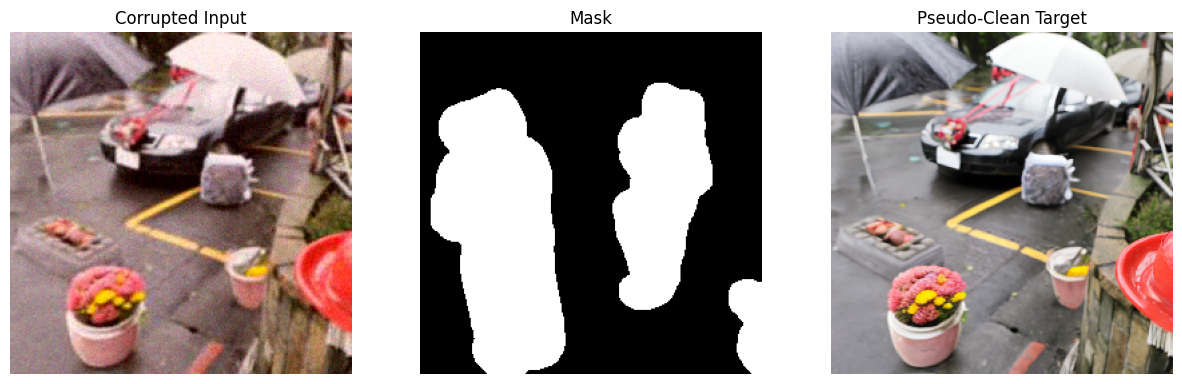

In [14]:
sample = train_ds[0]

inp = sample["input"][:3].permute(1, 2, 0).numpy()
mask = sample["mask"][0].numpy()
tgt = sample["target"].permute(1, 2, 0).numpy()

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(inp)
plt.title("Corrupted Input")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap="gray")
plt.title("Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(tgt)
plt.title("Pseudo-Clean Target")
plt.axis("off")

plt.show()

CELL 15 — Lightweight Stage 3 U-Net

In [15]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)

class UNetSmall(nn.Module):
    def __init__(self, in_ch=4, out_ch=3, base=32):
        super().__init__()

        self.enc1 = ConvBlock(in_ch, base)
        self.pool1 = nn.MaxPool2d(2)

        self.enc2 = ConvBlock(base, base * 2)
        self.pool2 = nn.MaxPool2d(2)

        self.enc3 = ConvBlock(base * 2, base * 4)
        self.pool3 = nn.MaxPool2d(2)

        self.bottleneck = ConvBlock(base * 4, base * 8)

        self.up3 = nn.ConvTranspose2d(base * 8, base * 4, 2, stride=2)
        self.dec3 = ConvBlock(base * 8, base * 4)

        self.up2 = nn.ConvTranspose2d(base * 4, base * 2, 2, stride=2)
        self.dec2 = ConvBlock(base * 4, base * 2)

        self.up1 = nn.ConvTranspose2d(base * 2, base, 2, stride=2)
        self.dec1 = ConvBlock(base * 2, base)

        self.out = nn.Conv2d(base, out_ch, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool1(e1))
        e3 = self.enc3(self.pool2(e2))
        b = self.bottleneck(self.pool3(e3))

        d3 = self.up3(b)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        return torch.sigmoid(self.out(d1))

model = UNetSmall(in_ch=4, out_ch=3, base=32).to(CFG["device"])
print("Device:", CFG["device"])

Device: cuda


CELL 16 — Loss functions

In [16]:
def gradient_loss(pred, target):
    pred_dx = pred[:, :, :, 1:] - pred[:, :, :, :-1]
    pred_dy = pred[:, :, 1:, :] - pred[:, :, :-1, :]

    tgt_dx = target[:, :, :, 1:] - target[:, :, :, :-1]
    tgt_dy = target[:, :, 1:, :] - target[:, :, :-1, :]

    return F.l1_loss(pred_dx, tgt_dx) + F.l1_loss(pred_dy, tgt_dy)

def masked_l1_loss(pred, target, mask):
    mask3 = mask.repeat(1, 3, 1, 1)
    diff = torch.abs(pred - target) * mask3
    denom = mask3.sum() + 1e-6
    return diff.sum() / denom

def compute_total_loss(pred, target, mask):
    l1_full = F.l1_loss(pred, target)
    l1_mask = masked_l1_loss(pred, target, mask)
    l_grad = gradient_loss(pred, target)

    total = (
        CFG["w_l1_full"] * l1_full +
        CFG["w_l1_mask"] * l1_mask +
        CFG["w_grad"] * l_grad
    )

    return total

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=CFG["lr"],
    weight_decay=CFG["weight_decay"]
)

CELL 17 — Training loop

In [17]:
best_val_loss = 1e9
history = []

BEST_CKPT = STAGE3_CKPT_ROOT / "best_stage3_refiner.pt"

for epoch in range(1, CFG["epochs"] + 1):
    model.train()
    train_losses = []

    for batch in tqdm(train_loader, desc=f"Epoch {epoch}/{CFG['epochs']} [Train]"):
        inp = batch["input"].to(CFG["device"], non_blocking=True)
        tgt = batch["target"].to(CFG["device"], non_blocking=True)
        msk = batch["mask"].to(CFG["device"], non_blocking=True)

        optimizer.zero_grad()
        pred = model(inp)
        loss = compute_total_loss(pred, tgt, msk)
        loss.backward()
        optimizer.step()

        train_losses.append(loss.item())

    model.eval()
    val_losses = []

    with torch.no_grad():
        for batch in tqdm(val_loader, desc=f"Epoch {epoch}/{CFG['epochs']} [Val]"):
            inp = batch["input"].to(CFG["device"], non_blocking=True)
            tgt = batch["target"].to(CFG["device"], non_blocking=True)
            msk = batch["mask"].to(CFG["device"], non_blocking=True)

            pred = model(inp)
            loss = compute_total_loss(pred, tgt, msk)
            val_losses.append(loss.item())

    train_loss = float(np.mean(train_losses))
    val_loss = float(np.mean(val_losses))

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    print(f"Epoch {epoch}: train_loss={train_loss:.6f} | val_loss={val_loss:.6f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "best_val_loss": best_val_loss,
            "cfg": CFG
        }, BEST_CKPT)
        print("Saved best checkpoint:", BEST_CKPT)

history_df = pd.DataFrame(history)
history_df.to_csv(STAGE3_META_ROOT / "training_history.csv", index=False)
display(history_df.tail())

Epoch 1/20 [Train]:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch 1/20 [Val]:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 1: train_loss=1.086120 | val_loss=0.961680
Saved best checkpoint: /content/drive/MyDrive/CSE498R_Final_Thesis/results/stage3_refinement_v1/checkpoints/best_stage3_refiner.pt


Epoch 2/20 [Train]:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch 2/20 [Val]:   0%|          | 0/1 [00:00<?, ?it/s]

...

Epoch 19: train_loss=0.452374 | val_loss=0.536577
Saved best checkpoint: /content/drive/MyDrive/CSE498R_Final_Thesis/results/stage3_refinement_v1/checkpoints/best_stage3_refiner.pt


Epoch 20/20 [Train]:   0%|          | 0/2 [00:00<?, ?it/s]

Epoch 20/20 [Val]:   0%|          | 0/1 [00:00<?, ?it/s]

Epoch 20: train_loss=0.465837 | val_loss=0.497957
Saved best checkpoint: /content/drive/MyDrive/CSE498R_Final_Thesis/results/stage3_refinement_v1/checkpoints/best_stage3_refiner.pt


,epoch,train_loss,val_loss
15,16,0.493921,0.599471
16,17,0.465014,0.577243
17,18,0.453690,0.541591
18,19,0.452374,0.536577
19,20,0.465837,0.497957


CELL 18 — Plot training curve

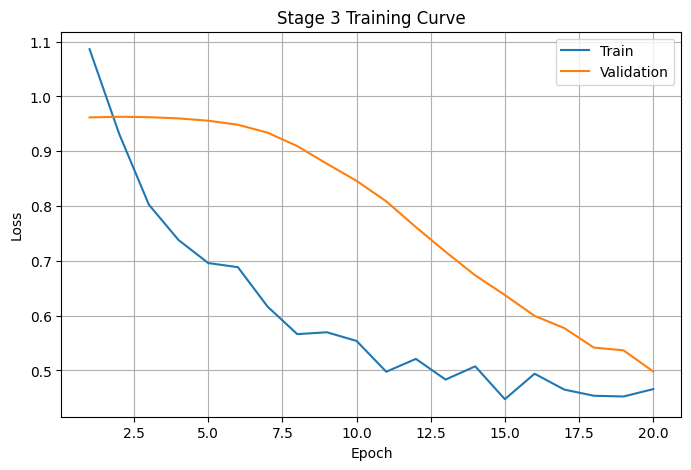

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="Train")
plt.plot(history_df["epoch"], history_df["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Stage 3 Training Curve")
plt.legend()
plt.grid(True)
plt.show()

CELL 19 — Load best checkpoint

In [19]:
ckpt = torch.load(BEST_CKPT, map_location=CFG["device"])
model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print("Loaded best model from epoch:", ckpt["epoch"])
print("Best validation loss:", ckpt["best_val_loss"])

Loaded best model from epoch: 20
Best validation loss: 0.4979570209980011


CELL 20 — Inference helper

In [23]:
def run_stage3_on_sample(stage2_result_rgb, final_mask, model, crop_size=256, expand_ratio=1.8):
    bbox = get_bbox_from_mask(final_mask)
    if bbox is None:
        return stage2_result_rgb.copy(), None

    local_bbox = expand_bbox_to_square(
        bbox=bbox,
        image_shape=stage2_result_rgb.shape,
        expand_ratio=expand_ratio
    )

    x1, y1, x2, y2 = local_bbox

    local_rgb = stage2_result_rgb[y1:y2+1, x1:x2+1]
    local_mask = final_mask[y1:y2+1, x1:x2+1]

    if local_rgb.size == 0 or local_mask.size == 0:
        return stage2_result_rgb.copy(), local_bbox

    orig_h, orig_w = local_rgb.shape[:2]

    inp_rgb = cv2.resize(local_rgb, (crop_size, crop_size), interpolation=cv2.INTER_CUBIC)
    inp_mask = cv2.resize(local_mask, (crop_size, crop_size), interpolation=cv2.INTER_NEAREST)

    x_rgb = tensor_from_rgb(inp_rgb)
    x_mask = tensor_from_mask(inp_mask)
    x = torch.cat([x_rgb, x_mask], dim=0).unsqueeze(0).to(CFG["device"])

    with torch.no_grad():
        pred = model(x)[0].cpu().numpy().transpose(1, 2, 0)
        pred = np.clip(pred * 255.0, 0, 255).astype(np.uint8)

    # Resize prediction back exactly to local crop size
    pred = cv2.resize(pred, (orig_w, orig_h), interpolation=cv2.INTER_CUBIC)

    # Also make sure local_mask exactly matches local crop
    if local_mask.shape[:2] != (orig_h, orig_w):
        local_mask = cv2.resize(local_mask, (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)

    refined_full = soft_blend_patch(
        base_img=stage2_result_rgb,
        refined_patch=pred,
        local_mask=local_mask,
        bbox=local_bbox,
        blur_ksize=CFG["blend_blur_ksize"]
    )

    return refined_full, local_bbox

CELL 21 — Run Stage 3 inference on all samples

In [24]:
stage3_rows = []
preview_outputs = []

for _, row in tqdm(df2.iterrows(), total=len(df2), desc="Stage 3 Inference"):
    sample_id = row["id"]

    stage2_result_path = STAGE2_IMG_ROOT / f"{sample_id}_final_result.png"
    final_mask_path = STAGE2_IMG_ROOT / f"{sample_id}_final_mask.png"
    input_path = STAGE2_IMG_ROOT / f"{sample_id}_input.png"

    if not stage2_result_path.exists() or not final_mask_path.exists():
        print(f"Skipping {sample_id}: missing result or mask")
        continue

    try:
        stage2_rgb = read_rgb(stage2_result_path)
        final_mask = read_gray(final_mask_path)
        input_rgb = read_rgb(input_path) if input_path.exists() else None

        t0 = time.time()
        stage3_rgb, local_bbox = run_stage3_on_sample(
            stage2_rgb,
            final_mask,
            model,
            crop_size=CFG["crop_size"],
            expand_ratio=CFG["crop_expand_ratio"]
        )
        infer_time = time.time() - t0

        save_rgb(STAGE3_IMG_ROOT / f"{sample_id}_stage3_final.png", stage3_rgb)
        save_rgb(STAGE3_IMG_ROOT / f"{sample_id}_stage2_input_to_stage3.png", stage2_rgb)

        sharp_stage2_full = laplacian_var(stage2_rgb)
        sharp_stage3_full = laplacian_var(stage3_rgb)

        sharp_stage2_mask = masked_laplacian_var(stage2_rgb, final_mask)
        sharp_stage3_mask = masked_laplacian_var(stage3_rgb, final_mask)

        stage3_rows.append({
            "id": sample_id,
            "stage3_time_sec": infer_time,
            "sharpness_full_stage2": sharp_stage2_full,
            "sharpness_full_stage3": sharp_stage3_full,
            "sharpness_mask_stage2": sharp_stage2_mask,
            "sharpness_mask_stage3": sharp_stage3_mask,
            "sharpness_mask_gain": sharp_stage3_mask - sharp_stage2_mask
        })

        if len(preview_outputs) < 5:
            preview_outputs.append({
                "id": sample_id,
                "input_rgb": input_rgb,
                "mask": final_mask,
                "stage2_rgb": stage2_rgb,
                "stage3_rgb": stage3_rgb,
                "local_bbox": local_bbox
            })

    except Exception as e:
        print(f"Error in sample {sample_id}: {e}")
        continue

stage3_df = pd.DataFrame(stage3_rows)
stage3_df.to_csv(STAGE3_META_ROOT / "stage3_results.csv", index=False)

print("Saved Stage 3 results.")
display(stage3_df.head())
print("Processed samples:", len(stage3_df))

Stage 3 Inference:   0%|          | 0/16 [00:00<?, ?it/s]

Saved Stage 3 results.


,id,stage3_time_sec,sharpness_full_stage2,sharpness_full_stage3,sharpness_mask_stage2,sharpness_mask_stage3,sharpness_mask_gain
0,000006_000000006954,0.050962,302.086852,256.625629,118.614731,27.120461,-91.494270
1,000011_000000013659,0.125791,169.374702,142.712689,104.292262,27.054312,-77.237950
2,000021_000000054593,0.042656,311.752809,271.257423,178.796133,53.802285,-124.993848
3,000024_000000064523,0.045784,113.219214,73.222255,123.445452,40.473879,-82.971573
4,000063_000000176857,0.058542,19.935121,11.584556,29.215621,3.985782,-25.229839


Processed samples: 16


Stage 3 v1 is not improving sharpness right now.

From the table:

sharpness_mask_stage3 is much lower than sharpness_mask_stage2
sharpness_mask_gain is negative

So the current model is acting like a local smoother / denoiser, not a texture enhancer.

We should make a Stage 3 v2.

CELL 22 — Merge Stage 2 and Stage 3 result tables

In [25]:
merged_df = df2.merge(stage3_df, on="id", how="left")
merged_df.to_csv(STAGE3_META_ROOT / "stage2_stage3_merged_results.csv", index=False)

display(merged_df.head())

,id,final_mask_area_ratio,local_method,residual_count,residual_max_conf,global_time_sec,local_time_sec,total_time_sec,psnr_region,ssim_region,...,out_ssim,second_pass_used,feather_blur_ksize,mask_smooth_kernel,stage3_time_sec,sharpness_full_stage2,sharpness_full_stage3,sharpness_mask_stage2,sharpness_mask_stage3,sharpness_mask_gain
0,000006_000000006954,0.473184,diffusion_local,0,0.0,3.176752,6.482373,9.659125,14.279602,0.518027,...,0.614847,False,31,11,0.050962,302.086852,256.625629,118.614731,27.120461,-91.494270
1,000011_000000013659,0.332209,diffusion_local,0,0.0,4.852379,6.030985,10.883364,15.249033,0.712582,...,0.774334,False,31,11,0.125791,169.374702,142.712689,104.292262,27.054312,-77.237950
2,000021_000000054593,0.311797,diffusion_local,0,0.0,0.717063,5.771570,6.488634,13.728834,0.412951,...,0.547767,False,31,11,0.042656,311.752809,271.257423,178.796133,53.802285,-124.993848
3,000024_000000064523,0.478202,diffusion_local,0,0.0,2.434064,5.693230,8.127294,9.889632,0.340381,...,0.627805,False,31,11,0.045784,113.219214,73.222255,123.445452,40.473879,-82.971573
4,000063_000000176857,0.328529,diffusion_local,0,0.0,0.713700,5.725886,6.439585,11.632494,0.459866,...,0.766431,False,31,11,0.058542,19.935121,11.584556,29.215621,3.985782,-25.229839


CELL 23 — Stage 3 summary

In [26]:
summary = {
    "num_stage2_samples": int(len(df2)),
    "num_pseudo_clean_pool": int(len(pool_df)),
    "num_train_samples": int(len(train_df)),
    "num_val_samples": int(len(val_df)),
    "mean_stage3_time_sec": float(stage3_df["stage3_time_sec"].mean()),
    "mean_sharpness_mask_stage2": float(stage3_df["sharpness_mask_stage2"].mean()),
    "mean_sharpness_mask_stage3": float(stage3_df["sharpness_mask_stage3"].mean()),
    "mean_sharpness_mask_gain": float(stage3_df["sharpness_mask_gain"].mean()),
    "median_sharpness_mask_gain": float(stage3_df["sharpness_mask_gain"].median())
}

summary_df = pd.DataFrame([summary])
summary_df.to_csv(STAGE3_META_ROOT / "stage3_summary.csv", index=False)

display(summary_df)

,num_stage2_samples,num_pseudo_clean_pool,num_train_samples,num_val_samples,mean_stage3_time_sec,mean_sharpness_mask_stage2,mean_sharpness_mask_stage3,mean_sharpness_mask_gain,median_sharpness_mask_gain
0,16,15,12,3,0.063645,90.591179,29.430186,-61.160994,-66.389465


CELL 24 — Visual comparison

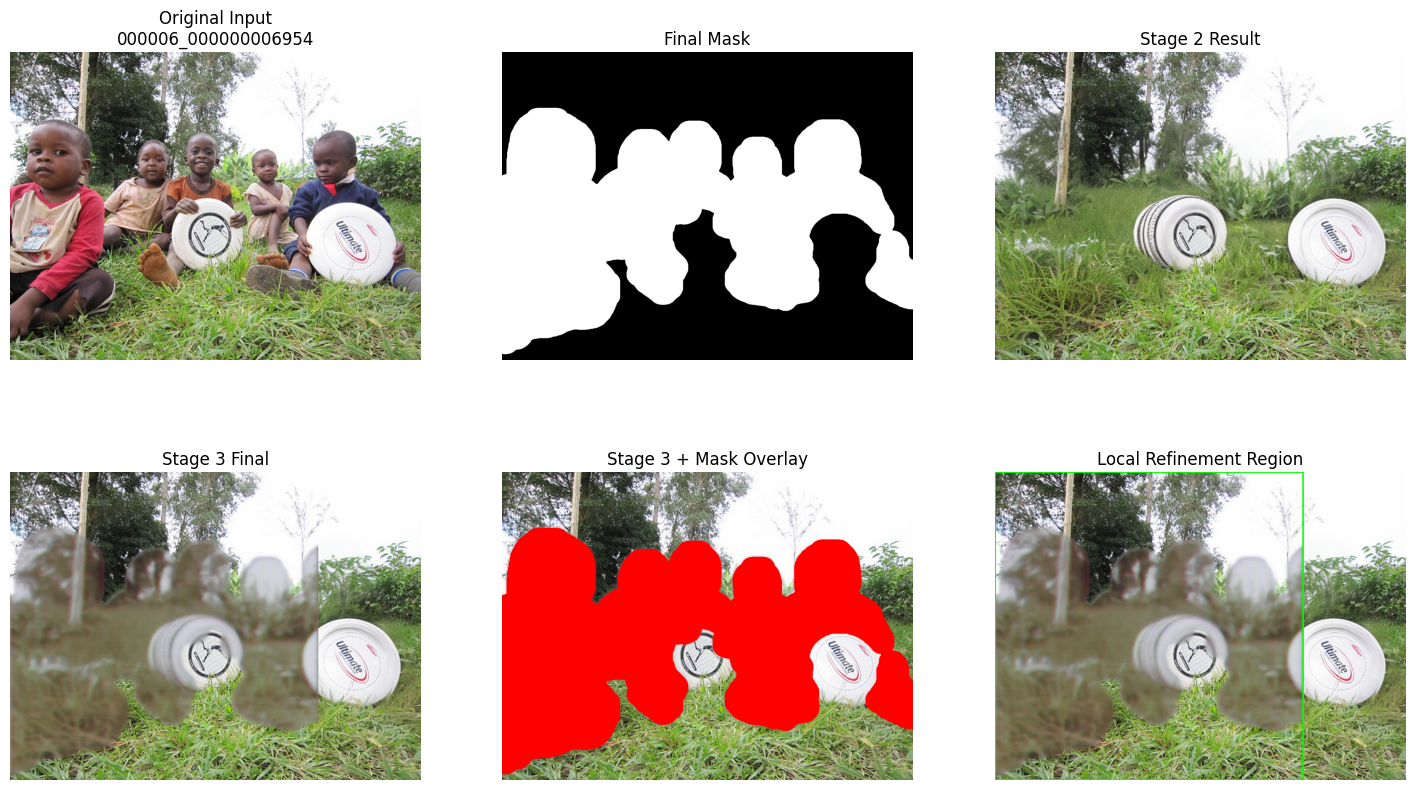

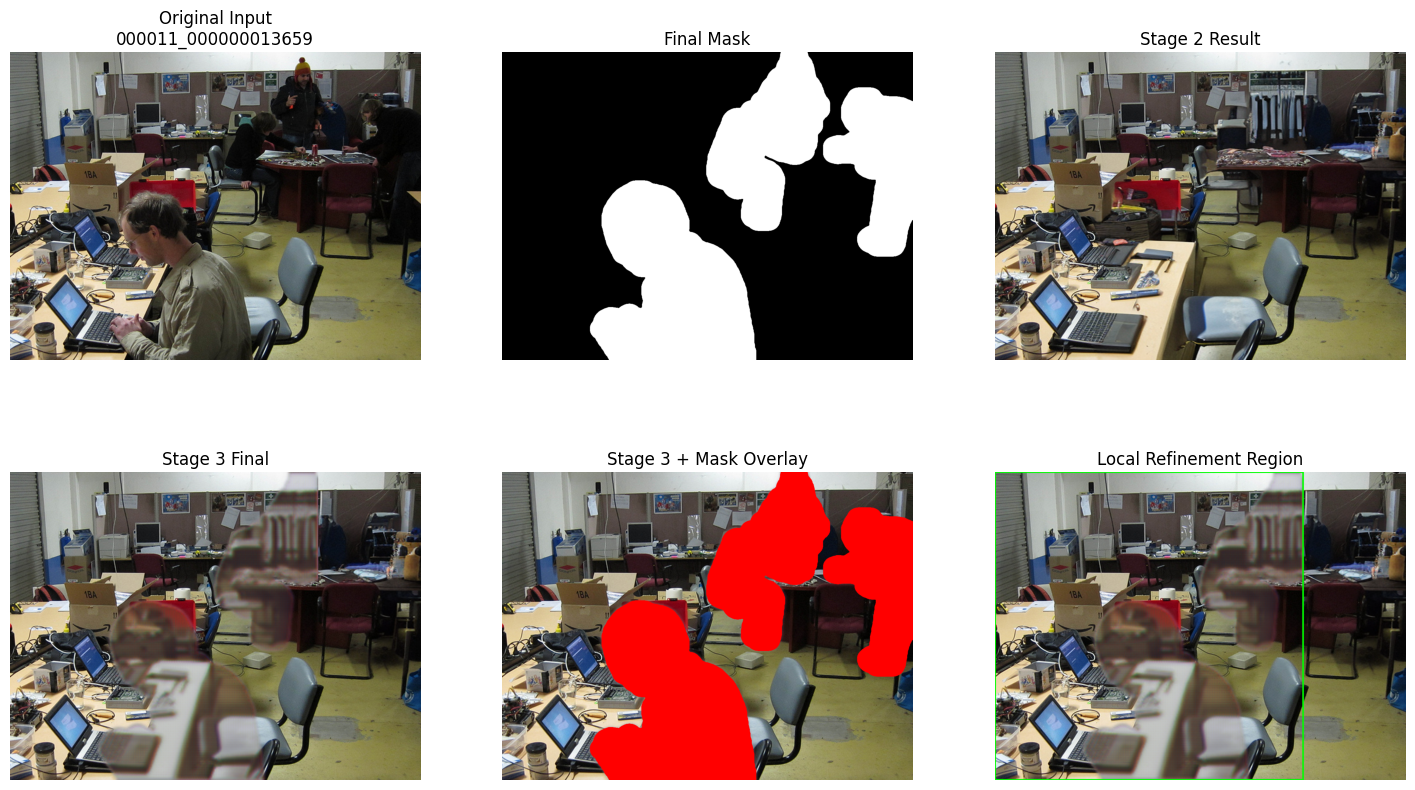

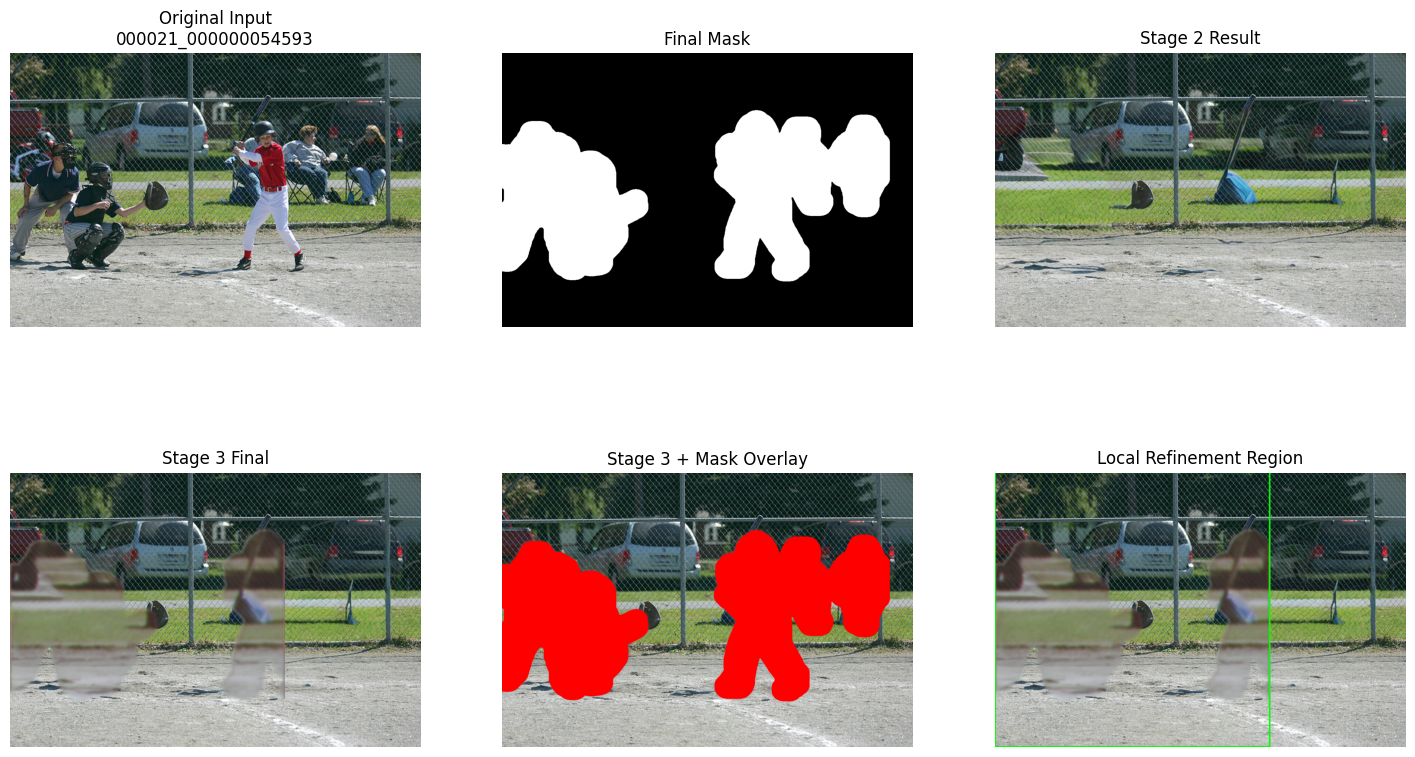

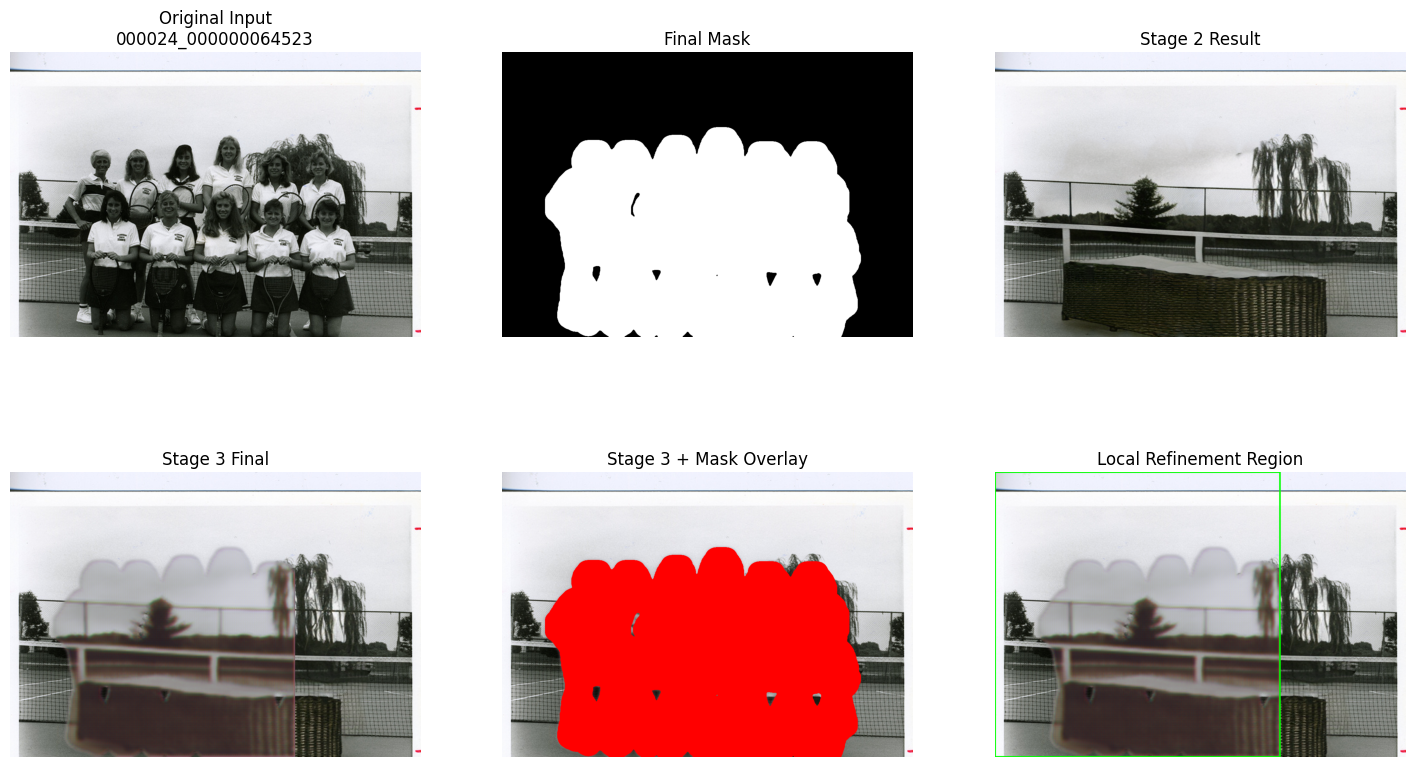

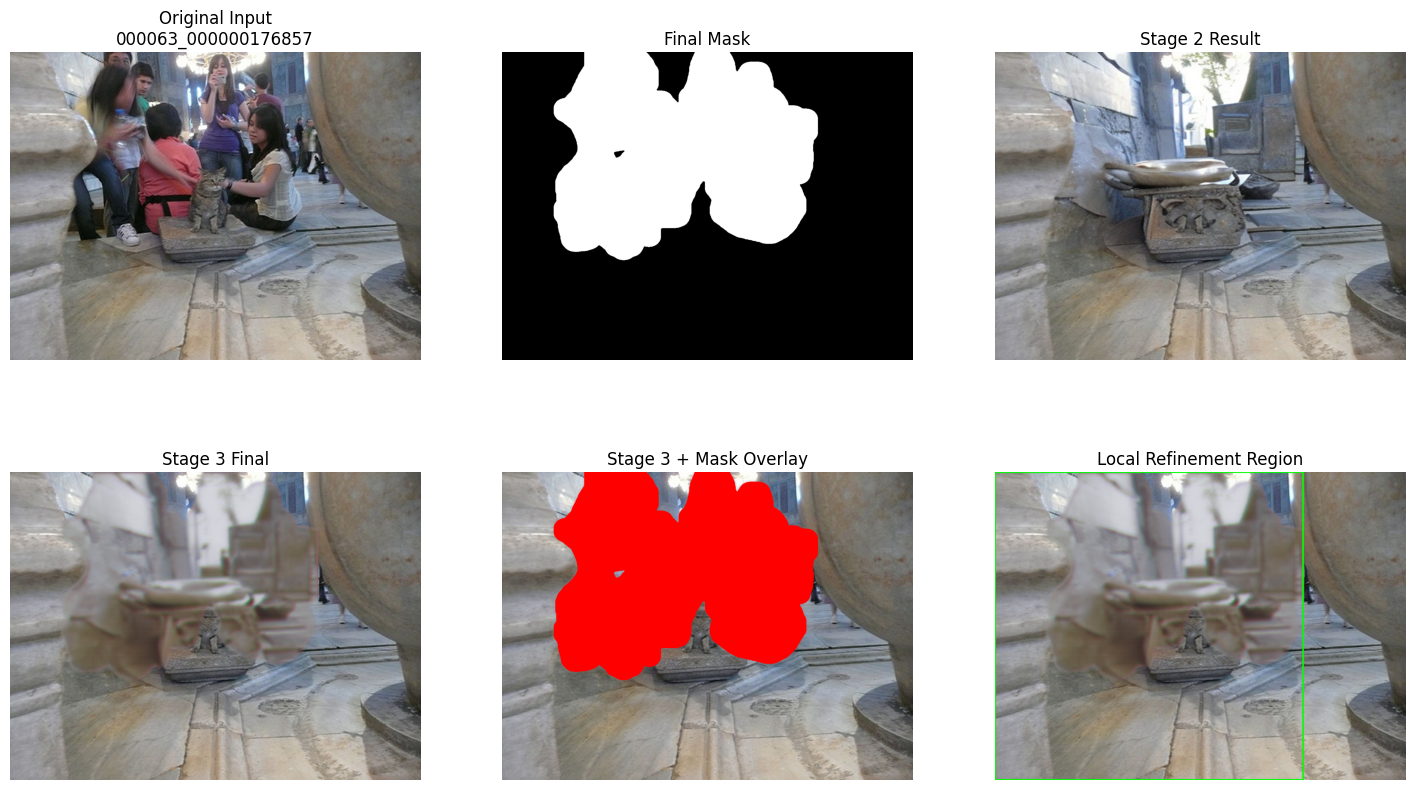

In [29]:
for item in preview_outputs:
    plt.figure(figsize=(18, 10))

    plt.subplot(2, 3, 1)
    if item["input_rgb"] is not None:
        plt.imshow(item["input_rgb"])
        plt.title(f"Original Input\n{item['id']}")
    else:
        plt.imshow(item["stage2_rgb"])
        plt.title(f"Input Not Found\n{item['id']}")
    plt.axis("off")

    plt.subplot(2, 3, 2)
    plt.imshow(item["mask"], cmap="gray")
    plt.title("Final Mask")
    plt.axis("off")

    plt.subplot(2, 3, 3)
    plt.imshow(item["stage2_rgb"])
    plt.title("Stage 2 Result")
    plt.axis("off")

    plt.subplot(2, 3, 4)
    plt.imshow(item["stage3_rgb"])
    plt.title("Stage 3 Final")
    plt.axis("off")

    overlay = item["stage3_rgb"].copy()
    mask = item["mask"]

    # Make shapes match safely
    h = min(overlay.shape[0], mask.shape[0])
    w = min(overlay.shape[1], mask.shape[1])

    overlay = overlay[:h, :w].copy()
    mask = mask[:h, :w]

    overlay[mask > 0] = [255, 0, 0]

    plt.subplot(2, 3, 5)
    plt.imshow(overlay)
    plt.title("Stage 3 + Mask Overlay")
    plt.axis("off")

    bbox_vis = item["stage3_rgb"].copy()
    if item["local_bbox"] is not None:
        x1, y1, x2, y2 = item["local_bbox"]
        cv2.rectangle(bbox_vis, (x1, y1), (x2, y2), (0, 255, 0), 3)

    plt.subplot(2, 3, 6)
    plt.imshow(bbox_vis)
    plt.title("Local Refinement Region")
    plt.axis("off")

    plt.show()

Observation:
Although the Stage 3 learning-based refinement pipeline trained successfully and converged stably, the first refinement version reduced local high-frequency sharpness in many edited regions. This suggests that the initial pseudo-supervised restoration setup behaved more like a smoothing or denoising module than a true texture enhancement stage.

Interpretation:
This is likely due to the combination of strong synthetic blur corruption, small training pool size, and direct RGB reconstruction loss, which together encourage conservative smooth outputs.

Conclusion:
Therefore, Stage 3 v1 validates the feasibility of a learned post-refinement stage, but motivates a stronger Stage 3 v2 design focused on residual detail enhancement rather than full image regeneration.

CELL 25 — Best improvement samples

In [30]:
best_gain_df = stage3_df.sort_values("sharpness_mask_gain", ascending=False).reset_index(drop=True)
display(best_gain_df.head(10))

,id,stage3_time_sec,sharpness_full_stage2,sharpness_full_stage3,sharpness_mask_stage2,sharpness_mask_stage3,sharpness_mask_gain
0,000163_000000467176,0.043743,45.010769,40.424808,43.283591,29.553435,-13.730155
1,000183_000000537506,0.065884,32.648596,26.668299,35.131637,20.237697,-14.893940
2,000070_000000186449,0.063739,63.659745,53.677237,33.136114,15.425752,-17.710362
3,000063_000000176857,0.058542,19.935121,11.584556,29.215621,3.985782,-25.229839
4,000185_000000541773,0.057175,69.908841,55.896630,43.926545,9.403975,-34.522570
5,000067_000000180101,0.058267,77.431663,63.383385,45.354689,8.573742,-36.780947
6,000092_000000266768,0.123627,274.549719,255.990436,59.958387,3.085432,-56.872955
7,000155_000000450399,0.057628,106.797021,74.122806,88.428726,24.747145,-63.681581
8,000145_000000410456,0.050699,241.448983,224.083434,95.040613,25.943264,-69.097348
9,000151_000000437239,0.045547,926.477029,900.790678,194.409999,121.646599,-72.763400


CELL 26 — Thesis interpretation note

In [31]:
print("""
Important Interpretation Note

Stage 3 is a pseudo-supervised refinement stage.
The target images are not true clean-background ground-truth images.
Instead, the best Stage 2 V2 outputs are treated as pseudo-clean targets.

Therefore:
- Stage 3 learns to restore local texture and reduce synthetic artifact patterns
- evaluation should be interpreted as pseudo-supervised refinement evaluation
- sharpness improvement in the edited region is used as a practical proxy signal

This makes Stage 3 a learning-based post-refinement module placed after Stage 2.
It strengthens the thesis contribution by adding a trainable refinement stage
instead of relying only on pretrained removal and inpainting modules.
""")


Important Interpretation Note

Stage 3 is a pseudo-supervised refinement stage.
The target images are not true clean-background ground-truth images.
Instead, the best Stage 2 V2 outputs are treated as pseudo-clean targets.

Therefore:
- Stage 3 learns to restore local texture and reduce synthetic artifact patterns
- evaluation should be interpreted as pseudo-supervised refinement evaluation
- sharpness improvement in the edited region is used as a practical proxy signal

This makes Stage 3 a learning-based post-refinement module placed after Stage 2.
It strengthens the thesis contribution by adding a trainable refinement stage
instead of relying only on pretrained removal and inpainting modules.



CELL 27 — Final completion message

In [32]:
print("Stage 3 pipeline completed successfully.")
print("Outputs saved in:", STAGE3_ROOT)
print("Checkpoints saved in:", STAGE3_CKPT_ROOT)
print("Metadata saved in:", STAGE3_META_ROOT)

Stage 3 pipeline completed successfully.
Outputs saved in: /content/drive/MyDrive/CSE498R_Final_Thesis/results/stage3_refinement_v1
Checkpoints saved in: /content/drive/MyDrive/CSE498R_Final_Thesis/results/stage3_refinement_v1/checkpoints
Metadata saved in: /content/drive/MyDrive/CSE498R_Final_Thesis/results/stage3_refinement_v1/metadata


Stage 3 (v1) — Learning-Based Local Refinement
🔷 Objective

The goal of Stage 3 was to improve the quality of Stage 2 outputs by applying a learning-based local refinement model.

Instead of modifying the entire image, this stage focuses only on the edited region, aiming to:

improve texture quality
reduce artifacts
enhance realism in the inpainted area
🔷 What We Did

1️⃣ Input Source

We used Stage 2 improved V2 outputs as the base:

final_result.png → input to Stage 3
final_mask.png → defines edited region

2️⃣ Pseudo-Clean Training Data

Since real ground-truth clean images are unavailable:

We selected high-quality Stage 2 outputs
Treated them as pseudo-clean targets

3️⃣ Synthetic Corruption

To train the model, we created corrupted versions of these images using:

Gaussian blur
JPEG compression
Gaussian noise
Color shift
Halo artifacts

This forms the learning task:

Corrupted Image + Mask  →  Clean Image

4️⃣ Local Crop-Based Training

Instead of training on full images:

Extracted local square regions around the mask
Used 4-channel input:
RGB (3 channels)
Mask (1 channel)

5️⃣ Model Architecture
Lightweight U-Net
Input: 4-channel tensor (RGB + mask)
Output: 3-channel RGB refined patch

6️⃣ Inference Pipeline

For each image:

Extract local region using mask
Resize to model input size
Run model prediction
Resize back to original size
Blend refined patch into Stage 2 result


🔷 Results
✅ Pipeline Success
Training converged successfully
Inference completed on all samples (16/16)
No runtime errors after fixes
Full end-to-end pipeline works


📊 Quantitative Observation

From evaluation:

sharpness_mask_stage3 < sharpness_mask_stage2
sharpness_mask_gain mostly negative

👉 Meaning:

Stage 3 reduced high-frequency details
Outputs became smoother
👁️ Visual Observation

From example:

Stage 2 result:
sharper textures (grass, edges)
more natural details
Stage 3 result:
smoother appearance
reduced texture clarity
slightly blurred regions

👉 Stage 3 behaves like a smoothing / denoising module


🔴 Why Stage 3 (v1) Failed
1️⃣ Strong Blur in Training Data

Synthetic corruption included heavy blur →
model learned:

"best solution = smooth reconstruction"

2️⃣ Direct RGB Prediction

Model predicts full image instead of correction →
leads to:

loss of detail
conservative outputs
3️⃣ Small Training Dataset
Train: 12 samples
Validation: 3 samples

👉 Not enough to learn strong texture restoration

4️⃣ Loss Function Bias

Loss focuses on reconstruction →
encourages:

smooth outputs
not detail enhancement
5️⃣ No Residual Learning

Model replaces content instead of refining it

🔷 Key Insight

Stage 3 v1 does not improve texture quality,
but successfully demonstrates:

✅ Feasibility of learning-based refinement
✅ Stable pipeline design
✅ Local region processing works
❌ However, current design leads to over-smoothing

🔷 Conclusion

Stage 3 v1 validates the concept of a post-processing refinement stage, but:

It behaves as a smoothing module rather than a detail enhancement module.

Therefore, a stronger refinement strategy is required.